# Notebook 9 - Data Transformation
Sprint 5 - Data Cleaning & Data Preprocessing

In this notebook I learn how to change the **shape** of a distribution with a mathematical transformation. I cover the log, square root, power, Box-Cox and Yeo-Johnson transformations, how to handle skewed data, and how these are different from normalization and standardization (Notebook 8). For every technique I compare the distribution before and after.

**Dataset:** Telco Customer Churn, after Notebooks 2 to 8. I use the same encoded training and test data and the same split as in Notebook 8. The continuous columns are `tenure`, `MonthlyCharges` and `TotalCharges`.

**Important:** Box-Cox and Yeo-Johnson **learn** a parameter (lambda) from the data. So they must be fitted on the training data only, and applied to the test data with the same lambda.

**Demo data:** The real Telco columns are only mildly skewed (`TotalCharges` is the one that matters). So for a few topics (left-skewed data, negative values) I use small demo series that I generate. They are always labelled as demo.

**Rule:** `df` (raw data) is never changed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.width", 200)

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")   # raw data, never modified

def fix_data_types(data):
    # Notebook 2
    out = data.copy()
    out["TotalCharges"] = pd.to_numeric(out["TotalCharges"], errors="coerce")
    out["SeniorCitizen"] = out["SeniorCitizen"].astype(bool)
    for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
        out[col] = out[col].map({"Yes": True, "No": False})
    for col in ["gender", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                "Contract", "PaymentMethod", "Churn"]:
        out[col] = out[col].astype("category")
    return out

def handle_missing_values(data):
    # Notebook 3
    out = data.copy()
    new_customer = out["tenure"] == 0
    out.loc[new_customer, "TotalCharges"] = out.loc[new_customer, "TotalCharges"].fillna(0.0)
    return out

def handle_duplicates(data, key="customerID", order_col="tenure"):
    # Notebook 4
    out = data.copy()
    audit = []
    out[key] = out[key].astype(str).str.strip().str.upper()
    exact = out.duplicated(keep="first")
    audit.append(out[exact].assign(reason="exact duplicate"))
    out = out[~exact]
    older = out.sort_values(order_col, kind="stable").duplicated(subset=key, keep="last").reindex(out.index)
    audit.append(out[older].assign(reason="older version of the same " + key))
    out = out[~older]
    return out, pd.concat(audit)

df_valid, _ = handle_duplicates(handle_missing_values(fix_data_types(df)))

# ---- encoding of Notebook 7
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

contract_order = ["Month-to-month", "One year", "Two year"]
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
service_cols = ["MultipleLines"] + addons
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
bool_cols = ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]

def prepare_B(data):
    out = data.copy()
    for c in service_cols:
        out[c] = out[c].astype(str).replace({"No internet service": "No", "No phone service": "No"})
        out[c] = (out[c] == "Yes").astype(int)
    out[bool_cols] = out[bool_cols].astype(int)
    out["gender"] = out["gender"].astype(str).map({"Male": 0, "Female": 1})
    for c in ["InternetService", "PaymentMethod", "Contract"]:
        out[c] = out[c].astype(str)
    return out

encoder = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("onehot", OneHotEncoder(handle_unknown="ignore"), ["InternetService", "PaymentMethod"]),
    ("contract", OrdinalEncoder(categories=[contract_order], handle_unknown="use_encoded_value", unknown_value=-1), ["Contract"]),
    ("keep", "passthrough", bool_cols + ["gender"] + service_cols),
], verbose_feature_names_out=False)

X = df_valid.drop(columns=["customerID", "Churn"])
y = (df_valid["Churn"] == "Yes").astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

encoder.fit(prepare_B(X_train))
def encode(data):
    arr = encoder.transform(prepare_B(data))
    arr = arr.toarray() if hasattr(arr, "toarray") else arr
    return pd.DataFrame(arr, columns=encoder.get_feature_names_out(), index=data.index)

X_train_enc, X_test_enc = encode(X_train), encode(X_test)
print("Encoded train:", X_train_enc.shape, "| encoded test:", X_test_enc.shape)

Encoded train: (5634, 24) | encoded test: (1409, 24)


## 1. Problems from Sprint 4 Related to Transformation

| # | Problem | Why it exists | Planned fix |
|---|---|---|---|
| 1 | `TotalCharges` is right skewed | many new customers, few very long-term ones | test power transformations |
| 2 | `TotalCharges` has zeros (the new customers of Notebook 3) | structural zero, not an error | use a transformation that accepts zero (`log1p`, Yeo-Johnson) |
| 3 | In Notebook 6 `log1p` gave a skew that is too negative | the logarithm is too strong for this column | compare the strengths and let the data choose lambda |
| 4 | Scaling (Notebook 8) does not change the skew | scalers are linear | a transformation must come **before** the scaling |
| 5 | `MonthlyCharges` has two groups of customers (a low and a high plan group) | two different kinds of plans | a power transformation cannot fix a bimodal shape, so do not apply it blindly |

## 2. Why Transform Data?

**Concept:** A transformation applies a mathematical function to every value of a column, for example `log(x)`, to change the **shape** of its distribution. It is used because:
- **Skew:** a long tail pulls the mean away from the typical value, and a few large values dominate the squared errors of a linear model.
- **Non-normality:** linear regression, logistic regression, LDA and many statistical tests work best when features (or residuals) are close to a bell shape.
- **Multiplicative effects:** if a value changes by percentages (money, counts), the logarithm turns the percentages into equal steps.
- **Unequal variance:** big values often have a bigger spread, and a transformation can make the spread more even.

Trees are not affected, because they only use the order of the values.

**Examples:**
- Simple: incomes of 20,000, 30,000 and 5,000,000: the logarithm brings the last value closer to the others.
- Real-world: earthquake magnitudes and sound loudness are measured on log scales.
- Business: the revenue of customers, where a few customers pay a hundred times more.
- AI/ML: a linear model with a skewed feature gives a few rows a very large influence.

**Implementation:** I measure the skewness and the kurtosis of the three continuous columns of the training data, and I look at the histogram and at the QQ plot (a QQ plot compares the data with a normal distribution: the points are on the line if the data is normal).

        column  min    max  skewness  excess kurtosis
        tenure  0.0   72.0     0.237           -1.387
MonthlyCharges 18.4  118.8    -0.224           -1.260
  TotalCharges  0.0 8684.8     0.949           -0.265


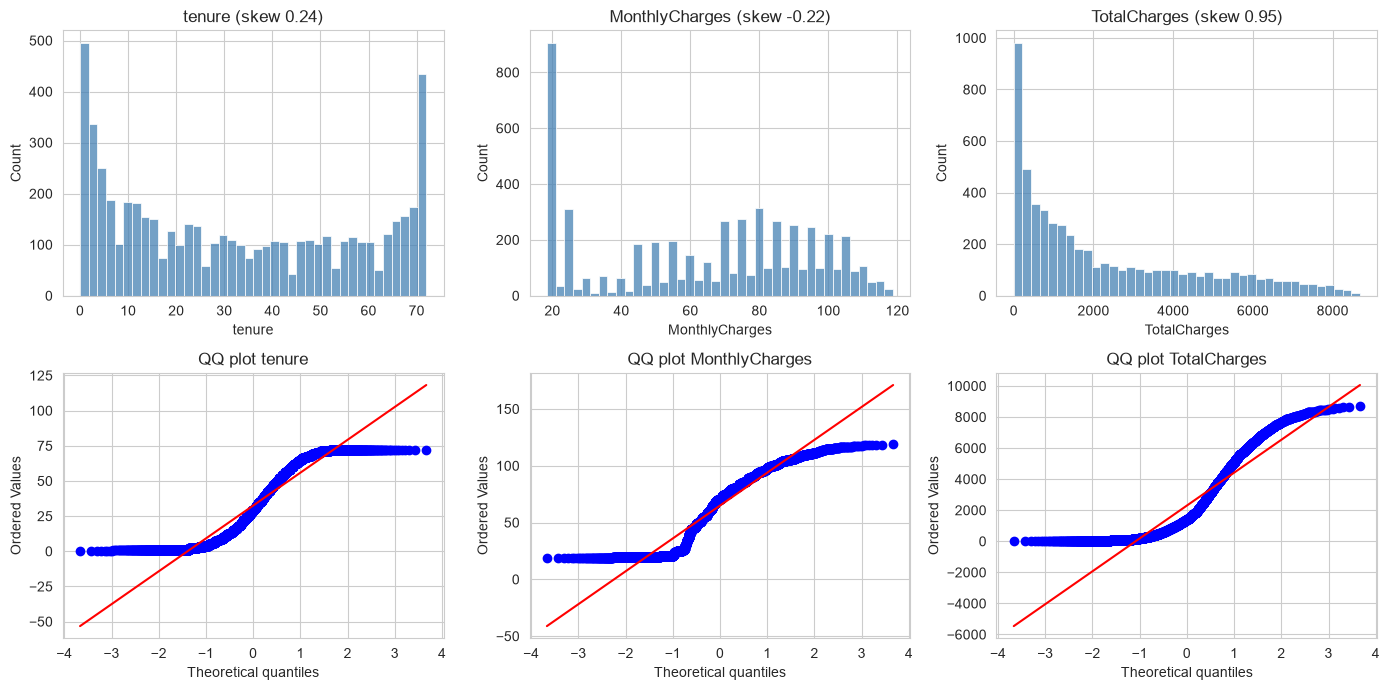

In [2]:
rows = []
for c in num_cols:
    s = X_train_enc[c]
    rows.append((c, round(s.min(), 1), round(s.max(), 1), round(s.skew(), 3), round(s.kurt(), 3)))
print(pd.DataFrame(rows, columns=["column", "min", "max", "skewness", "excess kurtosis"]).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for k, c in enumerate(num_cols):
    sns.histplot(X_train_enc[c], bins=40, ax=axes[0, k], color="steelblue")
    axes[0, k].set_title(c + " (skew " + str(round(X_train_enc[c].skew(), 2)) + ")")
    stats.probplot(X_train_enc[c], dist="norm", plot=axes[1, k])
    axes[1, k].set_title("QQ plot " + c)
plt.tight_layout()
plt.show()

**What the code does:**
- For the three continuous training columns it prints the minimum, maximum, skewness and excess kurtosis.
- The top row of the figure draws the histograms. The bottom row draws QQ plots with `stats.probplot`: it sorts the data and plots it against the values that a normal distribution would have. A perfect normal distribution lies on the straight line.

**Why this method was used:** The skewness is one number that says how asymmetric the distribution is (0 is symmetric, positive means a long right tail), and the kurtosis says how heavy the tails are. A number can hide a shape, so I also look at the histogram. The QQ plot is the best visual test of "is this normal", and it shows where the data leaves the line (the tails or the middle). I use only the training data, because a decision about a transformation uses the data.

**Output meaning:** `tenure` is close to symmetric (it is almost flat between 0 and 72, so the QQ plot is an S-shape, but the skew is near 0). `MonthlyCharges` has a skew near 0 as well, but on the real data its histogram has two groups (look at it in your run), which no power transformation can fix. `TotalCharges` has the clear positive skew, a long right tail, and the right end of its QQ plot goes above the line.

**Insight obtained:** A low skewness number does not mean "normal". `tenure` and `MonthlyCharges` are symmetric but not bell shaped. Only `TotalCharges` has the kind of problem that a power transformation is made for.

**Effect on ML:** I will focus on `TotalCharges`. For the other two columns, scaling (Notebook 8) is enough.

## 3. Handling Skewed Data

**Concept:** The first step is to measure the skew and its direction.

| Skewness | Meaning |
|---|---|
| between -0.5 and 0.5 | approximately symmetric |
| 0.5 to 1 (or -1 to -0.5) | moderately skewed |
| above 1 (or below -1) | highly skewed |

The direction decides the tool:
- **Right (positive) skew** (a long tail to the right): log, square root, or a power below 1.
- **Left (negative) skew** (a long tail to the left): first **reflect** the data (`max + 1 - x`), which turns it into a right skew, and then use the tools above. Or use a power above 1 (the square).
- The tool for one direction makes the other direction worse.

**Examples:**
- Simple: incomes are right skewed (a few very high incomes).
- Real-world: exam scores on an easy exam are left skewed (many high scores).
- Business: customer lifetime value is right skewed.
- AI/ML: the direction of the skew must be checked before a transformation is chosen.

**Implementation:** I use two demo series (generated by me): a right-skewed series, and its mirror image as a left-skewed series.

             data         transformation  skewness
right-skewed demo               original      2.89
right-skewed demo                    log     -0.06
 left-skewed demo               original     -2.89
 left-skewed demo   log (the wrong tool)    -18.30
 left-skewed demo      reflect, then log     -0.02
 left-skewed demo square (power above 1)     -1.84


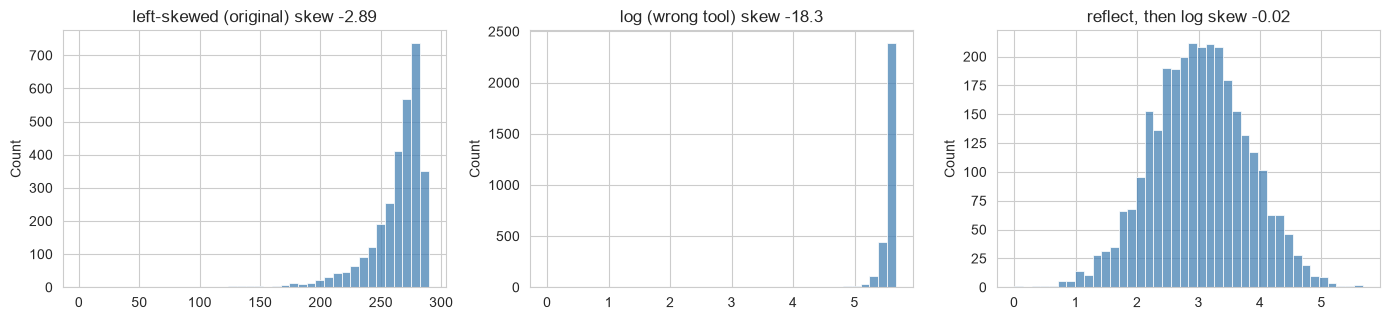

In [3]:
def skew(s):
    return round(float(pd.Series(s).skew()), 2)

rng = np.random.default_rng(4)
right = pd.Series(rng.lognormal(3, 0.8, 3000))              # DEMO: right skewed
left = right.max() + 1 - right                               # DEMO: the mirror image, left skewed

rows = [
    ("right-skewed demo", "original", skew(right)),
    ("right-skewed demo", "log", skew(np.log(right))),
    ("left-skewed demo", "original", skew(left)),
    ("left-skewed demo", "log (the wrong tool)", skew(np.log(left))),
    ("left-skewed demo", "reflect, then log", skew(np.log(left.max() + 1 - left))),
    ("left-skewed demo", "square (power above 1)", skew(left ** 2)),
]
print(pd.DataFrame(rows, columns=["data", "transformation", "skewness"]).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
for ax, (name, v) in zip(axes, [("left-skewed (original)", left), ("log (wrong tool)", np.log(left)), ("reflect, then log", np.log(left.max() + 1 - left))]):
    sns.histplot(v, bins=40, ax=ax, color="steelblue"); ax.set_title(name + " skew " + str(skew(v)))
plt.tight_layout()
plt.show()

**What the code does:**
- It creates a right-skewed demo series (a log-normal distribution, typical for money), and a left-skewed series by reflecting it: `max + 1 - x`.
- It applies different transformations and prints the skewness of each result: the log on the right-skewed data, and on the left-skewed data the log (wrong), the reflection followed by the log, and the square.
- It draws three histograms of the left-skewed data: the original, after the log, and after the reflection plus log.

**Why this method was used:** The mirror image has exactly the opposite skew, so it is a clean test of the rule "the direction decides the tool". Reflecting with `max + 1 - x` gives positive values only, which the log needs. I show the wrong tool on purpose, because it is a very common mistake.

**Output meaning:** The log fixes the right-skewed series (the skew goes close to 0). On the left-skewed series the log makes the skew **worse** (more negative), because the log compresses the large values, and the large values are the dense side. The reflection followed by the log brings the skew close to 0. The square helps only a little (the skew is still clearly negative), because a power of 2 is a weak correction for such a strong skew.

**Effect on ML:** `TotalCharges` is right skewed, so the right-skew tools are the correct family. For every column the skew direction must be checked first.

## 4. Log Transformation

**Concept:** `log(x)` replaces each value by its logarithm. It turns multiplication into addition, so equal percentages become equal steps, and it strongly compresses large values. It needs `x > 0`. For data with zeros I use `log1p(x) = log(1 + x)`, which is defined for `x >= 0` and gives 0 for 0. The inverse is `expm1`.

- **When to use:** strongly right-skewed positive data (money, counts, durations), multiplicative relations.
- **When not to use:** data with negative values (without a shift), data that is already symmetric, or when the skew is only mild (the log can over-correct).
- **Advantages:** simple, strong, easy to explain ("percent change"), invertible.
- **Limitations:** needs positive values, can over-correct a mild skew, and the shift for zeros (`+1`) is arbitrary and changes the result when the unit changes.

**Examples:**
- Simple: log10 of 10, 100 and 1000 gives 1, 2 and 3.
- Real-world: the Richter scale of earthquakes.
- Business: the logarithm of the revenue of a customer.
- AI/ML: the standard first try for money and count features.

**Implementation:**

Zeros in TotalCharges (train): 8 (the new customers of Notebook 3)
np.log(0) = -inf -> the plain log cannot be used on the zeros

Skewness: original 0.95 -> log1p -0.82
Inverse works (expm1 gives back the original values): True
Range after log1p: 0.0 to 9.07
Values now on the LOW side of the IQR rule (the new tail): 8


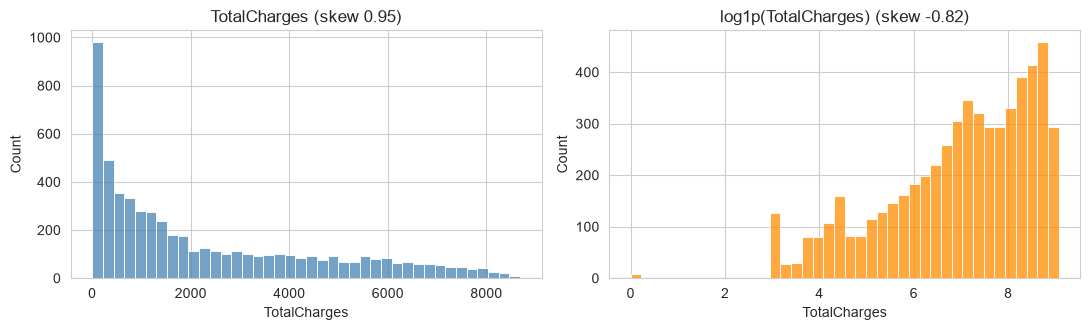

In [4]:
tc = X_train_enc["TotalCharges"]
print("Zeros in TotalCharges (train):", int((tc == 0).sum()), "(the new customers of Notebook 3)")

with np.errstate(divide="ignore"):
    print("np.log(0) =", np.log(0.0), "-> the plain log cannot be used on the zeros")

log1p = np.log1p(tc)
print("\nSkewness: original", skew(tc), "-> log1p", skew(log1p))
print("Inverse works (expm1 gives back the original values):", bool(np.allclose(np.expm1(log1p), tc)))
print("Range after log1p:", round(log1p.min(), 2), "to", round(log1p.max(), 2))

q1, q3 = log1p.quantile([0.25, 0.75])
low_tail = int((log1p < q1 - 1.5 * (q3 - q1)).sum())
print("Values now on the LOW side of the IQR rule (the new tail):", low_tail)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(tc, bins=40, ax=axes[0], color="steelblue");    axes[0].set_title("TotalCharges (skew " + str(skew(tc)) + ")")
sns.histplot(log1p, bins=40, ax=axes[1], color="darkorange"); axes[1].set_title("log1p(TotalCharges) (skew " + str(skew(log1p)) + ")")
plt.tight_layout()
plt.show()

**What the code does:**
- It counts the zeros in the training `TotalCharges`, and shows that `np.log(0)` is minus infinity.
- It applies `np.log1p`, prints the skewness before and after, checks that `np.expm1` gives back the original values, and prints the new range.
- It counts the values that are now on the **low** side of the IQR rule, to see if a new tail appeared.
- It draws the histograms before and after.

**Why this method was used:** `TotalCharges` has zeros, so the plain `log` is impossible, and `log1p` is the standard solution. I check the inverse because a transformation that cannot be undone is hard to explain to the business (for example "what does a value of 7.5 mean?" is answered by `expm1(7.5)`). I also count the low-side values, because a strong transformation can create a new problem on the other side.

**Output meaning:** `log1p` removes the right skew and goes **too far**: the skew becomes clearly negative, and the small totals of the new and the short-term customers form a long tail on the left. This is the over-correction that I saw in Notebook 6. The inverse check is True.

**Effect on ML:** The log is too strong for this column. I need a milder transformation, so I test the square root and then a general power transformation, where the data chooses the strength.

## 5. Square Root Transformation

**Concept:** `sqrt(x)` is a milder version of the log. It compresses the large values less strongly. It needs `x >= 0`, so it accepts zeros without any shift. It is also used for count data, because it makes the variance more equal.

- **When to use:** moderately right-skewed data with zeros, and counts.
- **When not to use:** negative values, or a very strong skew (the sqrt is too weak).
- **Advantages:** works with zeros, milder than the log, simple.
- **Limitations:** weaker, and the result is harder to explain ("square root of dollars").

**Examples:**
- Simple: the square root of 4, 9 and 100 is 2, 3 and 10.
- Real-world: the number of events per day.
- Business: the number of support calls per customer.
- AI/ML: a quick transformation between "nothing" and "log".

**Implementation:**

In [5]:
sqrt = np.sqrt(tc)
rows = [("original", skew(tc), round(tc.kurt(), 2)),
        ("square root", skew(sqrt), round(sqrt.kurt(), 2)),
        ("log1p", skew(log1p), round(log1p.kurt(), 2))]
print(pd.DataFrame(rows, columns=["version", "skewness", "excess kurtosis"]).to_string(index=False))
print("\nSquare root accepts the zeros without a shift. Inverse works:", bool(np.allclose(sqrt ** 2, tc)))

q1, q3 = sqrt.quantile([0.25, 0.75])
print("Values outside the IQR rule after the square root:", int(((sqrt < q1 - 1.5 * (q3 - q1)) | (sqrt > q3 + 1.5 * (q3 - q1))).sum()))

    version  skewness  excess kurtosis
   original      0.95            -0.26
square root      0.30            -1.08
      log1p     -0.82             0.08

Square root accepts the zeros without a shift. Inverse works: True
Values outside the IQR rule after the square root: 0


**What the code does:** It applies the square root to the training `TotalCharges`, and prints the skewness and the kurtosis of the original, the square root and the `log1p` in one table. It checks the inverse (squaring), and counts the values outside the IQR rule after the square root.

**Why this method was used:** The comparison table shows the **strength** of each transformation on the same data. Counting the values outside the IQR rule is the test that the transformation did not create a new tail.

**Output meaning:** The square root brings the skew close to 0 without going negative, so for this column it is a good fit, and it creates no new tail. The log1p is stronger and over-corrects. The order of strength is: original, square root, log1p.

**Effect on ML:** The right strength is between "nothing" and "log". Instead of trying transformations by hand, I let the data choose the strength with a power transformation.

## 6. Power Transformation

**Concept:** A power transformation raises the values to a power lambda: `x^lambda`. Lambda = 1 changes nothing, lambda = 0.5 is the square root, lambda close to 0 behaves like the log, and lambda = 2 is the square. A smaller lambda means a stronger correction of a right skew. So the square root and the log are only two points of one family, and the question is: which lambda is the best for my column?

- **When to use:** skewed positive data when the best strength is not known.
- **When not to use:** negative values (for a plain power), or data that is already symmetric.
- **Advantages:** flexible, one parameter, includes the log and the square root.
- **Limitations:** lambda must be chosen from the data (so learned on the training data), and the result is hard to interpret.

**Examples:**
- Simple: lambda = 0.5 means a square root.
- Real-world: choosing the strength of a lens correction.
- Business: choosing the best scale to compare the revenue of customers.
- AI/ML: Box-Cox and Yeo-Johnson (next sections) find lambda automatically.

**Implementation:** I scan lambda values from 0.05 to 1 on the training `TotalCharges` and look for the one with a skewness closest to 0.

lambda = 1.00 (no change): skew 0.95
lambda = 0.50 (square root): skew 0.3
Best lambda on the grid: 0.35 -> skew 0.034


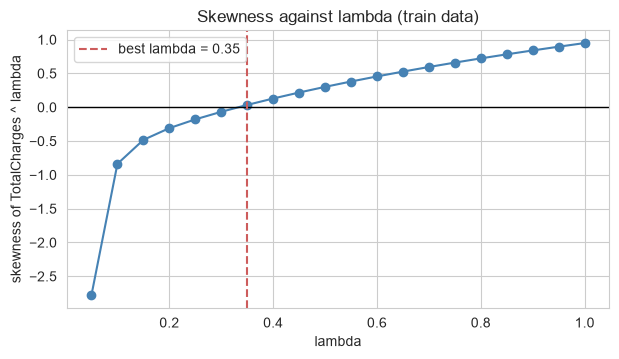

In [6]:
lambdas = np.round(np.arange(0.05, 1.01, 0.05), 2)
skews = [float(pd.Series(tc ** lam).skew()) for lam in lambdas]
best = lambdas[int(np.argmin(np.abs(skews)))]

print("lambda = 1.00 (no change): skew", skew(tc))
print("lambda = 0.50 (square root): skew", round(float(pd.Series(tc ** 0.5).skew()), 2))
print("Best lambda on the grid:", best, "-> skew", round(float(pd.Series(tc ** best).skew()), 3))

plt.figure(figsize=(7, 3.6))
plt.plot(lambdas, skews, marker="o", color="steelblue")
plt.axhline(0, color="black", linewidth=1)
plt.axvline(best, color="indianred", linestyle="--", label="best lambda = " + str(best))
plt.xlabel("lambda"); plt.ylabel("skewness of TotalCharges ^ lambda"); plt.legend(); plt.title("Skewness against lambda (train data)")
plt.show()

**What the code does:** It raises the training `TotalCharges` to every power from 0.05 to 1.00 in steps of 0.05, calculates the skewness each time, finds the lambda with the smallest absolute skewness (`argmin`), and draws the curve of the skewness against lambda, with the best value marked.

**Why this method was used:** The plot shows that the skewness changes smoothly with lambda, and that one value gives 0. This is the idea that Box-Cox and Yeo-Johnson use, but they use a better criterion (the maximum likelihood of a normal distribution) and not only the skewness. A simple grid is easy to understand and it shows why lambda must come from the data. The grid starts above 0 because lambda = 0 is the logarithm (a special case).

**Output meaning:** The curve goes down when lambda goes down. At lambda = 1 the skew is the original one, and it crosses 0 at a lambda around the square root, a bit below. This is consistent with the previous section: the square root is close to the best, and the log (lambda near 0) is too strong.

**Effect on ML:** The best strength is a number that is learned from the training data. It must be stored and used for the test data without being estimated again.

## 7. Box-Cox Transformation

**Concept:** Box-Cox is the power family with a log at lambda = 0: `(x^lambda - 1) / lambda` for lambda not 0, and `log(x)` for lambda = 0. Lambda is estimated by **maximum likelihood**: the value for which the transformed data is the closest to a normal distribution. It requires **strictly positive** data (`x > 0`).

- **When to use:** strictly positive, skewed data, when I want the data to choose the strength.
- **When not to use:** data with zeros or negative values.
- **Advantages:** automatic, well founded, includes the log.
- **Limitations:** fails with zeros and negatives, a shift (`x + 1`) is arbitrary, and the result is not easy to explain.

**Examples:**
- Simple: skewed positive prices.
- Real-world: the concentration of a chemical, always positive.
- Business: the monthly charge of a customer.
- AI/ML: `PowerTransformer(method="box-cox")`.

**Implementation:** First I apply it to `TotalCharges` as it is (it has zeros), and then with a shift of 1. I also verify the formula by hand.

In [7]:
from sklearn.preprocessing import PowerTransformer

# 1) the zeros stop Box-Cox
try:
    PowerTransformer(method="box-cox", standardize=False).fit(tc.to_frame())
except Exception as e:
    print("Box-Cox on TotalCharges with zeros ->", type(e).__name__)

# 2) with a shift of 1 (all values are positive now)
bc = PowerTransformer(method="box-cox", standardize=False).fit((tc + 1).to_frame())     # lambda learned on TRAIN only
lam = float(bc.lambdas_[0])
train_bc = pd.Series(bc.transform((tc + 1).to_frame()).ravel(), index=tc.index)
test_bc = pd.Series(bc.transform((X_test_enc["TotalCharges"] + 1).to_frame()).ravel(), index=X_test_enc.index)

print("\nLambda learned on train:", round(lam, 3))
print("Skewness: original", skew(tc), "-> Box-Cox train", skew(train_bc), "| test (train lambda)", skew(test_bc))

by_hand = ((tc + 1) ** lam - 1) / lam
print("Formula by hand equals PowerTransformer:", bool(np.allclose(by_hand, train_bc)))
print("Same result with scipy.stats.boxcox:", bool(np.allclose(stats.boxcox(tc + 1)[0], by_hand, atol=1e-3)))

Box-Cox on TotalCharges with zeros -> ValueError

Lambda learned on train: 0.258
Skewness: original 0.95 -> Box-Cox train -0.15 | test (train lambda) -0.14
Formula by hand equals PowerTransformer: True
Same result with scipy.stats.boxcox: True


**What the code does:**
- It tries `PowerTransformer(method="box-cox")` on the raw `TotalCharges`, and catches the error that appears because of the zeros.
- It adds 1 to every value, so all are positive, and fits the transformer on the **training** values. `lambdas_` stores the lambda that it found.
- It transforms the training values, and the test values with the training lambda, and prints the skewness of each.
- It calculates the formula `((x + 1)^lambda - 1) / lambda` by hand and checks that it is equal to the result of scikit-learn. It also compares with `scipy.stats.boxcox`.

**Why this method was used:** The first test shows the real limitation of Box-Cox: it refuses zeros, and `TotalCharges` has zeros that are legitimate (new customers). The shift by 1 makes it work, but the 1 is an arbitrary choice (a different shift gives a different lambda). Fitting on the training data and transforming the test data with the same lambda is the correct pattern. The check by hand shows that I understand what the function does, and not only how to call it.

**Output meaning:** The transformer stops with a `ValueError` on the zeros. With the shift it finds a lambda that is smaller than 1 (a correction between "nothing" and "log", close to the square root range), the skewness of the training data goes close to 0, and the test data (with the training lambda) also gets a skewness close to 0. The three ways of calculating give the same numbers.

**Effect on ML:** Box-Cox works for this column only after a shift that I have to choose. A method that handles zeros by itself is cleaner, and this is Yeo-Johnson.

## 8. Yeo-Johnson Transformation

**Concept:** Yeo-Johnson is a generalisation of Box-Cox that works with **zero and negative values**. It uses different formulas for `x >= 0` and `x < 0`. For `x >= 0` it is the same as Box-Cox of `x + 1`. Lambda is also estimated by maximum likelihood. It is the default choice of `PowerTransformer`.

- **When to use:** skewed data with zeros or negative values, or when I do not want to choose a shift.
- **When not to use:** data that is already symmetric, or when a simple log is enough and has a clear meaning.
- **Advantages:** no shift needed, handles all real numbers, automatic.
- **Limitations:** more complex, the result is hard to interpret, and a bimodal shape is not fixed.

**Examples:**
- Simple: a column with profits and losses.
- Real-world: temperatures below and above zero.
- Business: a monthly balance that can be negative.
- AI/ML: `PowerTransformer(method="yeo-johnson")`, the safest default.

**Implementation:**

In [8]:
yj = PowerTransformer(method="yeo-johnson", standardize=False).fit(tc.to_frame())      # lambda learned on TRAIN only
train_yj = pd.Series(yj.transform(tc.to_frame()).ravel(), index=tc.index)
test_yj = pd.Series(yj.transform(X_test_enc[["TotalCharges"]]).ravel(), index=X_test_enc.index)

print("Yeo-Johnson lambda:", round(float(yj.lambdas_[0]), 3), "| Box-Cox(x + 1) lambda:", round(lam, 3))
print("Largest difference between Yeo-Johnson(x) and Box-Cox(x + 1):", float(np.abs(train_yj - train_bc).max().round(6)), "(same thing for x >= 0)")
print("Zeros are accepted: Yeo-Johnson(0) =", float(yj.transform(pd.DataFrame({"TotalCharges": [0.0]}))[0][0]))
print("Skewness: original", skew(tc), "-> Yeo-Johnson train", skew(train_yj), "| test", skew(test_yj))
print("Inverse works:", bool(np.allclose(yj.inverse_transform(train_yj.to_frame()).ravel(), tc)))

# DEMO: a column with negative values (profits and losses), generated by me
rng = np.random.default_rng(6)
profit = pd.Series(np.where(rng.random(2000) < 0.7, rng.lognormal(3, 0.6, 2000), -rng.lognormal(2, 0.6, 2000)))
print("\nDEMO profit column: min", round(profit.min(), 1), "| max", round(profit.max(), 1), "| skew", skew(profit))
try:
    PowerTransformer(method="box-cox").fit(profit.to_frame())
except Exception as e:
    print("Box-Cox on negative values ->", type(e).__name__)
profit_yj = PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(profit.to_frame()).ravel()
print("Yeo-Johnson on the same column -> skew", skew(profit_yj))

Yeo-Johnson lambda: 0.258 | Box-Cox(x + 1) lambda: 0.258
Largest difference between Yeo-Johnson(x) and Box-Cox(x + 1): 7e-06 (same thing for x >= 0)
Zeros are accepted: Yeo-Johnson(0) = 0.0
Skewness: original 0.95 -> Yeo-Johnson train -0.15 | test -0.14
Inverse works: True

DEMO profit column: min -53.7 | max 145.2 | skew 0.94
Box-Cox on negative values -> ValueError
Yeo-Johnson on the same column -> skew 0.14


**What the code does:**
- It fits `PowerTransformer(method="yeo-johnson", standardize=False)` on the training `TotalCharges`, and transforms the training and the test values with the learned lambda.
- It prints the lambda next to the Box-Cox lambda, the largest difference between the two transformed columns, the result for the value 0, the skewness before and after, and checks the inverse.
- With a demo column of profits and losses (positive and negative values) it shows that Box-Cox stops with an error, and that Yeo-Johnson works and reduces the skew.

**Why this method was used:** For `TotalCharges` the comparison with Box-Cox is a useful check: for non-negative values Yeo-Johnson of `x` is Box-Cox of `x + 1`, so the two lambdas and the two results are practically the same. The difference is that Yeo-Johnson does not need me to choose the shift. The demo column proves the second advantage, with negative values. `standardize=False` is used here so that I can compare the pure transformation. The inverse check shows that the result can be translated back into the original units.

**Output meaning:** The two lambdas are almost equal, and the difference between the two transformed columns is close to 0. The zero is accepted and goes to 0. The skewness goes close to 0 on the training data and also on the test data. In the demo, Box-Cox fails on the negative values, and Yeo-Johnson reduces the skew.

**Effect on ML:** Yeo-Johnson is the cleanest choice for `TotalCharges`: no shift, it accepts the zeros of the new customers, the strength is learned from the training data, and it is invertible.

## 9. Normalization and Standardization Compared with Transformations

**Concept:** The two groups of methods do different things.

| | Normalization / standardization (Notebook 8) | Power transformations (this notebook) |
|---|---|---|
| Type of change | linear (shift and stretch) | non-linear |
| Changes the shape (skew) | no | yes |
| Changes the units / range | yes | yes |
| Learns from data | min, max, mean, std | lambda |
| Order of use | after the transformation | before the scaling |

`PowerTransformer(standardize=True)` does both in one step: the power transformation, and then the standardization of the result.

**Examples:**
- Simple: converting kilometres to miles (linear) against taking a logarithm (non-linear).
- Real-world: moving a curve (linear) against bending it (non-linear).
- Business: a report in thousands (linear) against a log scale (non-linear).
- AI/ML: first bend the shape, then give the column a mean of 0 and a std of 1.

**Implementation:**

In [9]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

col = tc.to_frame()
versions = {
    "original": tc,
    "MinMaxScaler": pd.Series(MinMaxScaler().fit_transform(col).ravel()),
    "StandardScaler": pd.Series(StandardScaler().fit_transform(col).ravel()),
    "RobustScaler": pd.Series(RobustScaler().fit_transform(col).ravel()),
    "Yeo-Johnson (standardize=False)": train_yj,
    "Yeo-Johnson (standardize=True)": pd.Series(PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(col).ravel()),
}
rows = [(n, round(v.mean(), 3), round(v.std(ddof=0), 3), round(v.skew(), 3)) for n, v in versions.items()]
print(pd.DataFrame(rows, columns=["method", "mean", "std", "skewness"]).to_string(index=False))

print("\nThe three linear scalers keep the skewness:", bool(np.allclose([skew(versions[n]) for n in ['MinMaxScaler', 'StandardScaler', 'RobustScaler']], skew(tc))))

                         method     mean      std  skewness
                       original 2299.335 2279.002     0.949
                   MinMaxScaler    0.265    0.262     0.949
                 StandardScaler    0.000    1.000     0.949
                   RobustScaler    0.263    0.664     0.949
Yeo-Johnson (standardize=False)   21.109    8.676    -0.147
 Yeo-Johnson (standardize=True)   -0.000    1.000    -0.147

The three linear scalers keep the skewness: True


**What the code does:** It applies three scalers from Notebook 8 and two versions of the Yeo-Johnson transformer (without and with standardization) to the training `TotalCharges`. It prints the mean, the standard deviation and the skewness of each version, and checks that the three scalers have the same skewness as the original.

**Why this method was used:** Putting the linear and the non-linear methods in one table shows the difference at once: the columns "mean" and "std" are changed by all methods, and the column "skewness" is changed only by the power transformation. This is the exact answer to the question "I scaled my column, why is it still skewed?".

**Output meaning:** The three scalers have different means and standard deviations but the same skewness as the original. Yeo-Johnson without standardization changes the skewness, but not the mean and the std in a controlled way. Yeo-Johnson with `standardize=True` gives a mean of 0, a std of 1 **and** a skewness close to 0.

**Effect on ML:** For a skewed column I use a transformation with `standardize=True`, or a transformation followed by a scaler. I never use only a scaler to fix a skew.

## 10. Distribution Before and After Transformation

transformation  skew train  kurtosis train  skew test  kurtosis test
      original       0.949          -0.265      1.022         -0.073
   square root       0.301          -1.077      0.333         -1.003
         log1p      -0.820           0.079     -0.843          0.203
 Box-Cox (x+1)      -0.147          -1.036     -0.138         -1.003
   Yeo-Johnson      -0.147          -1.036     -0.138         -1.003


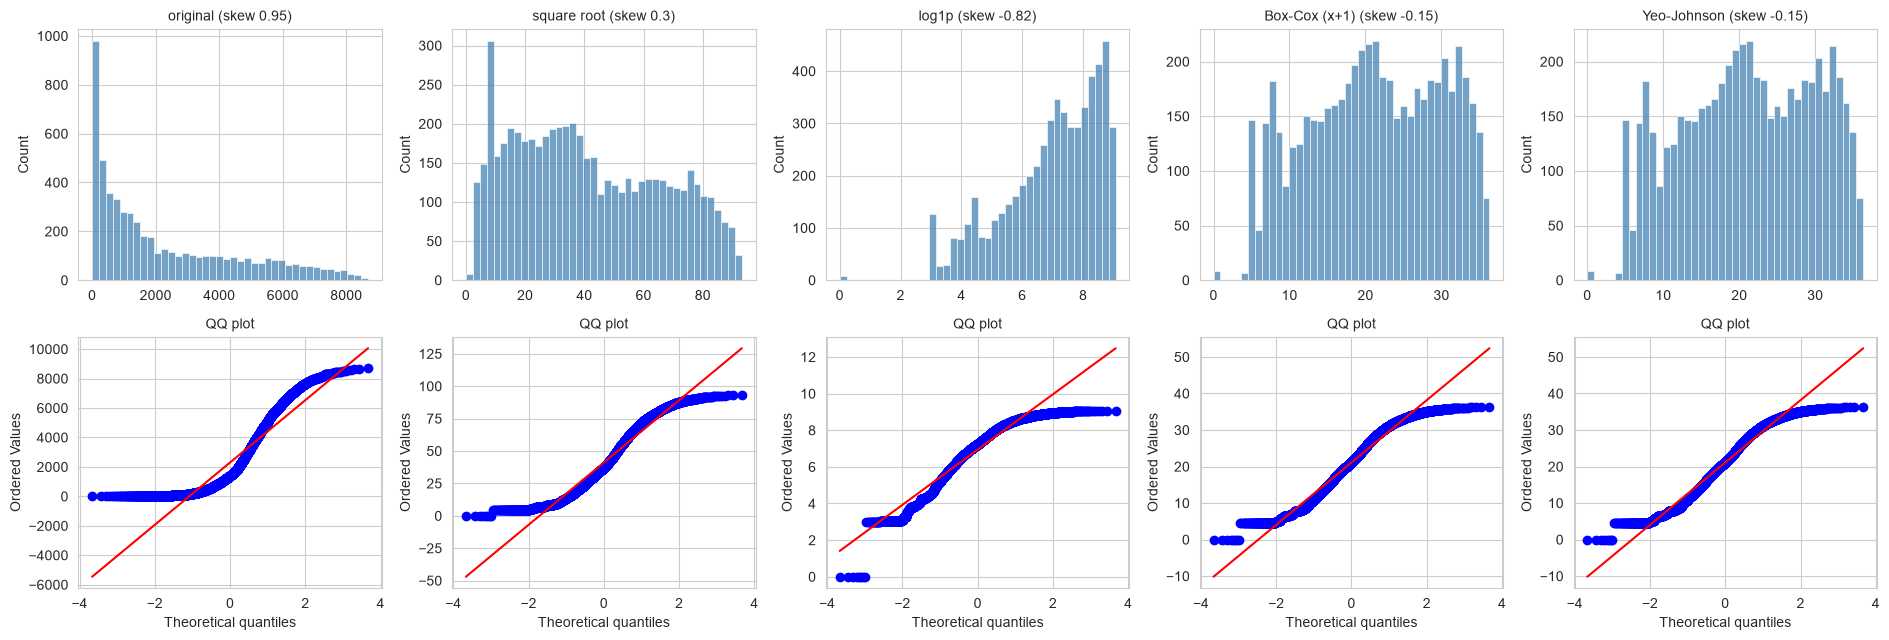

In [10]:
test_tc = X_test_enc["TotalCharges"]
candidates = {
    "original": (tc, test_tc),
    "square root": (np.sqrt(tc), np.sqrt(test_tc)),
    "log1p": (np.log1p(tc), np.log1p(test_tc)),
    "Box-Cox (x+1)": (train_bc, test_bc),
    "Yeo-Johnson": (train_yj, test_yj),
}

rows = []
for name, (tr, te) in candidates.items():
    rows.append((name, round(tr.skew(), 3), round(tr.kurt(), 3), round(te.skew(), 3), round(te.kurt(), 3)))
table = pd.DataFrame(rows, columns=["transformation", "skew train", "kurtosis train", "skew test", "kurtosis test"])
print(table.to_string(index=False))

fig, axes = plt.subplots(2, 5, figsize=(19, 6.5))
for k, (name, (tr, te)) in enumerate(candidates.items()):
    sns.histplot(tr, bins=40, ax=axes[0, k], color="steelblue")
    axes[0, k].set_title(name + " (skew " + str(round(tr.skew(), 2)) + ")", fontsize=10); axes[0, k].set_xlabel("")
    stats.probplot(tr, dist="norm", plot=axes[1, k])
    axes[1, k].set_title("QQ plot", fontsize=10)
plt.tight_layout()
plt.show()

**What the code does:**
- It collects five versions of `TotalCharges`: the original, the square root, the `log1p`, Box-Cox with the shift, and Yeo-Johnson. For each one it has the training and the test values (the test values are transformed with what was learned on the training data).
- It prints a table with the skewness and the kurtosis of train and test for each version.
- It draws a grid: the histogram of each version in the top row, and the QQ plot in the bottom row.

**Why this method was used:** The sprint asks to compare the distribution before and after, and a table and a picture give two views of the same result. The test columns are in the table to check that what was learned on the training data also works on data that was not used: if the test skewness is similar to the training skewness, the transformation generalises. The QQ plot shows the shape better than a single skewness number: it shows if the tails are still off the line.

**Output meaning:**
- **Original:** clear positive skew, and the QQ plot curves up at the right end.
- **Square root:** the skew is close to 0, and the QQ plot is much closer to the line.
- **log1p:** the skew is negative and the QQ plot bends in the opposite direction at the left end. This is the over-correction.
- **Box-Cox and Yeo-Johnson:** the skew is close to 0 and the two look the same. The test skewness is close to the training skewness in both cases.
- None of the versions is a perfect bell shape (the histogram has a large group at the low end, with the new and short-term customers), and the QQ plots show it. The transformation fixes the skew, not the whole shape.

**Insight obtained:** The best transformation is the one with the smallest skew **and** no new tail, and the data can choose it (Box-Cox and Yeo-Johnson), while the log is a guess that was too strong.

**Effect on ML:** The transformation of `TotalCharges` is learned on the training data, and the test data shows the same behaviour.

## 11. Effect on a Model

**Concept:** A transformation is useful only if it helps the model. I compare the logistic regression and the KNN with the `TotalCharges` untouched, with the square root, with the `log1p` and with Yeo-Johnson. The transformation is inside a pipeline, so lambda is learned in each training fold. After it, `TotalCharges` is standardized, and the other two continuous columns are standardized as well.

**Examples:**
- Simple: the same exam with a different way of preparing.
- Real-world: testing two recipes with the same ingredients.
- Business: a check that the transformation brings a benefit before it goes to production.
- AI/ML: cross-validation with the preprocessing inside the pipeline.

**Implementation:**

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def make_pipeline(transformer, model):
    pre = ColumnTransformer([
        ("total", Pipeline([("transform", transformer), ("scale", StandardScaler())]), ["TotalCharges"]),
        ("other", StandardScaler(), ["tenure", "MonthlyCharges"]),
    ], remainder="passthrough")
    return Pipeline([("pre", pre), ("model", model)])

transformers = {
    "none (only scaling)": FunctionTransformer(),
    "square root": FunctionTransformer(np.sqrt),
    "log1p": FunctionTransformer(np.log1p),
    "Yeo-Johnson": PowerTransformer(method="yeo-johnson", standardize=False),
}

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, transformer in transformers.items():
        lr = cross_val_score(make_pipeline(transformer, LogisticRegression(max_iter=2000)), X_train_enc, y_train, cv=cv, scoring="roc_auc")
        knn = cross_val_score(make_pipeline(transformer, KNeighborsClassifier(n_neighbors=15)), X_train_enc, y_train, cv=cv, scoring="roc_auc")
        rows.append((name, round(lr.mean(), 4), round(lr.std(), 4), round(knn.mean(), 4), round(knn.std(), 4)))
print(pd.DataFrame(rows, columns=["TotalCharges transformation", "AUC logistic", "std", "AUC KNN", "std "]).to_string(index=False))

TotalCharges transformation  AUC logistic    std  AUC KNN   std 
        none (only scaling)        0.8462 0.0118   0.8219 0.0191
                square root        0.8468 0.0121   0.8264 0.0167
                      log1p        0.8505 0.0131   0.8290 0.0181
                Yeo-Johnson        0.8498 0.0130   0.8278 0.0174


**What the code does:**
- `make_pipeline` builds a pipeline in which `TotalCharges` goes through a transformation and then a `StandardScaler`, `tenure` and `MonthlyCharges` go through a `StandardScaler`, and the other columns pass unchanged. The last step is the model.
- Four transformations are tested: none (identity, `FunctionTransformer()` without arguments), square root, `log1p` and Yeo-Johnson.
- For each of them it calculates the 5-fold cross-validated ROC AUC for a logistic regression and for a KNN, and prints the mean and the standard deviation.

**Why this method was used:** Everything is inside the pipeline, so the Yeo-Johnson lambda is learned again in each training fold, and the validation fold never influences it. I test a logistic regression (a linear model, that profits from a better shape) and a KNN (distance based). The standard deviation of the 5 folds tells how big a difference must be to be meaningful. I do not test a tree model, because it does not use the shape of a column.

**Output meaning:** The differences between the four versions are small, often smaller than the standard deviation of the folds. This is normal: only one column is transformed, the change of the shape is moderate, and the models are mainly driven by the other features (such as the contract). I read it as "the transformation does not hurt, and it can help the linear model a little", and not as a big gain. The numbers in your run can be different.

**Insight obtained:** A transformation is mainly a way to make the data well behaved for linear and distance-based models, and the gain in the score is usually small. The decision should also be based on the quality of the distribution and on the robustness.

**Effect on ML:** I choose the transformation for its stability (no over-correction, no shift, handles the zeros), and I do not expect a big jump in the score.

## 12. Decision and Final Transformed Data

**Concept:** The decision rule: transform a column when its skewness is clearly large (an absolute value above 0.75), and keep it unchanged otherwise. The transformation is Yeo-Johnson, because it accepts zeros, learns lambda from the training data, and is invertible.

**Examples:**
- Simple: bend only the column that is bent.
- Real-world: a mechanic only straightens the part that is bent.
- Business: a documented rule that can be applied to new data.
- AI/ML: the rule is part of the pipeline and uses only training statistics.

**Implementation:**

In [12]:
decisions = []
for c in num_cols:
    s = X_train_enc[c].skew()
    action = "Yeo-Johnson (standardize=True)" if abs(s) > 0.75 else "StandardScaler only"
    decisions.append((c, round(s, 3), action))
decision_table = pd.DataFrame(decisions, columns=["column", "skewness (train)", "decision"])
print(decision_table.to_string(index=False))

skewed = [c for c, s, a in decisions if a.startswith("Yeo")]
plain = [c for c in num_cols if c not in skewed]

final_transform = ColumnTransformer([
    ("power", PowerTransformer(method="yeo-johnson", standardize=True), skewed),
    ("scale", StandardScaler(), plain),
], remainder="passthrough", verbose_feature_names_out=False)
final_transform.fit(X_train_enc)                                  # learned on the TRAIN data only

def transform(data):
    arr = final_transform.transform(data)
    return pd.DataFrame(arr, columns=final_transform.get_feature_names_out(), index=data.index)[data.columns]

X_train_ready, X_test_ready = transform(X_train_enc), transform(X_test_enc)

summary = pd.DataFrame({
    "skew before (train)": X_train_enc[num_cols].skew(),
    "skew after (train)": X_train_ready[num_cols].skew(),
    "skew after (test)": X_test_ready[num_cols].skew(),
    "mean after (train)": X_train_ready[num_cols].mean(),
    "std after (train)": X_train_ready[num_cols].std(ddof=0),
}).round(3)
print()
print(summary)

others = [c for c in X_train_enc.columns if c not in num_cols]
pt = final_transform.named_transformers_["power"]
back = pt.inverse_transform(X_train_ready[skewed])
print("\nUnchanged columns identical:", bool(X_train_enc[others].equals(X_train_ready[others])))
print("Yeo-Johnson lambda(s) learned on train:", dict(zip(skewed, pt.lambdas_.round(3))))
print("Inverse recovers the original values:", bool(np.allclose(back, X_train_enc[skewed].to_numpy())))
print("Shape:", X_train_ready.shape, "| same columns in train and test:", list(X_train_ready.columns) == list(X_test_ready.columns),
      "| missing values:", int(X_train_ready.isna().sum().sum() + X_test_ready.isna().sum().sum()))

X_train_ready.assign(Churn=y_train).to_csv("telco_step9_train_ready.csv")
X_test_ready.assign(Churn=y_test).to_csv("telco_step9_test_ready.csv")
print("saved: transformed and scaled train and test")

        column  skewness (train)                       decision
        tenure             0.237            StandardScaler only
MonthlyCharges            -0.224            StandardScaler only
  TotalCharges             0.949 Yeo-Johnson (standardize=True)

                skew before (train)  skew after (train)  skew after (test)  mean after (train)  std after (train)
tenure                        0.237               0.237              0.248                -0.0                1.0
MonthlyCharges               -0.224              -0.224             -0.206                -0.0                1.0
TotalCharges                  0.949              -0.147             -0.138                -0.0                1.0

Unchanged columns identical: True
Yeo-Johnson lambda(s) learned on train: {'TotalCharges': np.float64(0.258)}
Inverse recovers the original values: True
Shape: (5634, 24) | same columns in train and test: True | missing values: 0
saved: transformed and scaled train and test


**What the code does:**
- It calculates the skewness of each continuous training column, and applies the decision rule: an absolute skewness above 0.75 means "Yeo-Johnson", otherwise only scaling. It prints the decision table.
- It builds a `ColumnTransformer`: `PowerTransformer(method="yeo-johnson", standardize=True)` for the skewed columns, a `StandardScaler` for the other continuous columns, and all the other columns pass unchanged. It is fitted on the **training** data.
- A helper function applies it to a dataframe and keeps the original column order. The code prints the skewness before and after (train and test), and the mean and the standard deviation after.
- It checks that the unchanged columns are identical, prints the learned lambda, verifies that `inverse_transform` recovers the original `TotalCharges`, checks the shapes and the missing values, and saves the result.

**Why this method was used:** The decision follows a written rule, and not a feeling, so that it can be repeated on new data and defended in the review. With `standardize=True` the transformed column is also centered and scaled, so the order "transform first, then scale" of this notebook is in one step. Only the skewed column is transformed. `tenure` and `MonthlyCharges` have a skewness near 0 and only need scaling, and a power transformation cannot fix the two groups of `MonthlyCharges`. The inverse check is for the interpretation of the results, and the `fit` on the training data only is the protection against leakage.

**Before:** `TotalCharges` has a positive skew, a large range and zeros.

**After:** `TotalCharges` has a skewness close to 0 in the training data and a similar value in the test data, a mean of 0 and a standard deviation of 1. The two other continuous columns are scaled as in Notebook 8, and the 21 other columns are identical. There are no missing values.

**Effect on ML:** The data set now has the best shape for linear and distance-based models: the numeric columns are scaled, and the skewed column is corrected. The tree models can use the encoded data of Notebook 7. All these steps will be connected in one pipeline in Notebook 14.

## 13. Documentation of the Decisions

**Decision 1 - Transform TotalCharges with Yeo-Johnson, fitted on the training data**

| Item | Documentation |
|---|---|
| Problem | `TotalCharges` is right skewed, has a long tail, and has zeros from the new customers. Scaling alone does not change the shape |
| Analysis | The skew comes from the customer base: many new customers and few very long-term ones. The zeros are structural (Notebook 3), not errors |
| Technique selected | `PowerTransformer(method="yeo-johnson", standardize=True)`, fitted on the training data |
| Reason | The `log1p` over-corrects (the skew becomes clearly negative and a new tail appears on the left). The square root is good but fixed. Box-Cox needs a shift of the zeros that I would have to choose. Yeo-Johnson accepts the zeros, learns the strength from the data, and is invertible |
| Implementation | Sections 4 to 8 for the comparison, and Section 12 for the final transformer |
| Result | The skewness is close to 0 on train and on test, the mean is 0 and the std is 1 |
| Impact | Linear and distance-based models get a better shaped feature, with no leakage, because lambda comes from the training data only. The gain in the score is expected to be small |

**Decision 2 - Do not transform tenure and MonthlyCharges**

| Item | Documentation |
|---|---|
| Problem | Should all three continuous columns be transformed? |
| Analysis | `tenure` and `MonthlyCharges` have a skewness near 0. `MonthlyCharges` has two groups of customers, and no power transformation fixes a two-group shape |
| Technique selected | Only the `StandardScaler` (Notebook 8) |
| Reason | A transformation without a problem adds complexity and makes the interpretation harder |
| Implementation | The decision rule of Section 12 (absolute skewness above 0.75) |
| Result | Only `TotalCharges` is transformed |
| Impact | The pipeline is simpler, and the two columns keep their meaning in months and in money |

# Summary

| Method | Formula | Use when | Avoid when |
|---|---|---|---|
| Log | `log(x)`, `log1p(x)` | strongly right-skewed positive data | negative values, mild skew (over-corrects) |
| Square root | `sqrt(x)` | moderate right skew, counts, zeros | strong skew, negative values |
| Power | `x^lambda` | the best strength is unknown | negative values |
| Box-Cox | `(x^lambda - 1) / lambda` | strictly positive skewed data | zeros and negative values |
| Yeo-Johnson | Box-Cox for `x >= 0`, a mirror for `x < 0` | zeros or negative values, safest default | already symmetric data |
| Reflect, then log | `log(max + 1 - x)` | left-skewed data | right-skewed data |
| Scaling (Notebook 8) | linear | any column, after the transformation | to fix a skew |

**Key findings on the Telco data:**
- Only `TotalCharges` is clearly skewed. `tenure` and `MonthlyCharges` have a skewness near 0, but `MonthlyCharges` has two groups, which a transformation cannot fix.
- The tool for a right skew makes a left skew worse, so the direction must be checked first.
- The `log1p` over-corrects `TotalCharges` (negative skew and a new tail on the left). The square root is milder and works better.
- Box-Cox does not accept the zeros, and Yeo-Johnson does. For non-negative values Yeo-Johnson of `x` is Box-Cox of `x + 1`.
- Scalers do not change the skewness. A power transformation does.
- The lambda is learned on the training data only, and the effect on the model score is small.

**What I learned:** A transformation changes the shape, a scaler changes the units, and they are used in this order. The strongest transformation is not the best one: the log is a guess and the power transformations let the data choose. And a transformation is a decision that needs a reason, as every other step in the preprocessing.

**Next:** Notebook 10 - Feature Selection.